<a href="https://colab.research.google.com/github/y-adulyasak/SCOA_PhD/blob/main/S11_SPO/DFL_PyEPO_shortest_path_and_MILP_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SPO+ with PyEPO: the shortest-path benchmark and our supplier MILP

**Professor: Yossiri Adulyasak**

**PhD Seminar (Decision-Focused Learning).** Companion to `DFL_MILP_SPO_example_S1.ipynb`.

**PyEPO** (Tang & Khalil, 2024) is a PyTorch library for end-to-end predict-then-optimize. It wraps an optimization
model so that SPO+ (and other decision-focused losses) can be used like any other loss in a PyTorch training loop:
the forward pass solves the optimization problem, the backward pass returns the SPO+ gradient $2\,(w^*(c) - w^*(2\hat c - c))$.

* **Part 1** reruns the shortest-path experiment of the SPO+ paper (Elmachtoub & Grigas, 2022) with PyEPO's built-in
  data generator and model: least squares and random forests (predict, then optimize) against SPO+.
* **Part 2** is a small toy: a template for putting your own model into PyEPO, applied to our supplier-selection MILP
  and trained on the four weeks of the MILP notebook, first with the linear model (it reproduces the three
  hand-computed SPO+ iterations exactly) and then with a small neural network.

Runs in Colab (CPU). The LP and
the MILP are Pyomo models solved with HiGHS, as in the other notebooks.

*References.* Elmachtoub, A. N., & Grigas, P. (2022). Smart "predict, then optimize". *Management Science*, 68(1), 9–26.
Tang, B., & Khalil, E. B. (2024). PyEPO: a PyTorch-based end-to-end predict-then-optimize library for linear and
integer programming. *Mathematical Programming Computation*, 16, 297–335.

## Setup

In [1]:
!pip install -q pyepo==2.2.7 "pyomo>=6.9" highspy

In [2]:
import os
os.environ["TQDM_DISABLE"] = "1"                   # silence PyEPO's progress bars (set before any import)
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import pyomo.environ as pe
import pyepo
from pyepo.model.omo import optOmoModel
from torch.utils.data import DataLoader
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
pd.set_option("display.precision", 3)
print("PyEPO", pyepo.__version__, "| PyTorch", torch.__version__)

INK, MUTED, GRID_C, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"      # chart ink, grid and axis colours
def tidy_axes(a):
    a.grid(axis="y", color=GRID_C, lw=0.8); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
    for side in ("left", "bottom"): a.spines[side].set_color(AXIS)
    a.tick_params(colors=MUTED); a.yaxis.label.set_color(MUTED); a.xaxis.label.set_color(MUTED)

PyEPO 2.2.7 | PyTorch 2.14.1+cpu


---
# Part 1: The shortest-path benchmark of the SPO+ paper

**The decision.** A $5 \times 5$ grid of nodes with 40 edges, each pointing east or south. We travel from the top-left to
the bottom-right corner on the cheapest path, an LP whose optimal solutions are paths ($w_e = 1$ if edge $e$ is used):

$$\min_w\ c^\top w \quad \text{s.t. flow conservation},\quad 0 \le w_e \le 1.$$

**The data** (PyEPO's `genData`, the generator of the SPO+ paper). Each instance has $p = 5$ features
$x \sim N(0, I)$; a fixed random 0/1 matrix $B$ decides which features move which edge:

$$c_e = \frac{\big(\tfrac{1}{\sqrt p}(Bx)_e + 3\big)^{\deg} + 1}{3.5^{\deg}} \cdot \varepsilon_e, \qquad
\varepsilon_e \sim U[1 - \bar\varepsilon,\ 1 + \bar\varepsilon].$$

With $\deg = 1$ the expected cost is linear in $x$; the larger the degree, the more a linear model is
**misspecified**. That is the knob the paper turns.

| | SPO+ paper | here (Colab size) |
|---|---|---|
| training instances $n$ | 100, 1,000, 5,000 | 100, 1,000 |
| degree | 1, 2, 4, 6, 8 | 1, 2, 4, 6 |
| noise half-width $\bar\varepsilon$ | 0, 0.5 | 0.5 |
| test instances, repetitions | 10,000, 50 | 300, 1 |

**The PyEPO recipe** (the same steps as in Part 2):

1. `pyepo.data.shortestpath.genData(n, p, grid, deg, noise_width)` draws features $x$ and costs $c$.
2. `pyepo.model.omo.shortestPathModel(grid, solver="highs")` is the LP, built into PyEPO (a Pyomo model).
3. `pyepo.data.dataset.optDataset(model, x, c)` solves every instance once and stores $w^*(c)$ and $z^*(c)$.
4. A PyTorch model, the loss `pyepo.func.SPOPlus(model)`, and an ordinary training loop.
5. `pyepo.metric.regret(predictor, model, test_loader)`: the normalized regret
   $\sum_i \big(c_i^\top w(\hat c_i) - z^*(c_i)\big) / \sum_i z^*(c_i)$ on new instances.

40 edges; cost of the shortest path 6.70


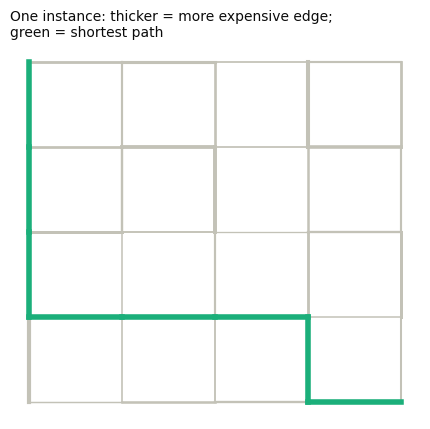

In [3]:
GRID, P_FEAT, NOISE = (5, 5), 5, 0.5
def new_sp_model():
    "step 2; each step below builds a fresh model, because a Pyomo model slows down after thousands of solves"
    return pyepo.model.omo.shortestPathModel(GRID, solver="highs")

X1, C1 = pyepo.data.shortestpath.genData(1, P_FEAT, GRID, deg=4, noise_width=NOISE, seed=135)   # step 1: one instance
sp_model = new_sp_model()
sp_model.setObj(C1[0]); path, length = sp_model.solve()
print(f"{sp_model.num_cost} edges; cost of the shortest path {length:.2f}")

fig, ax = plt.subplots(figsize=(4.4, 4.4))
for e, (u, v) in enumerate(sp_model.arcs):                     # node v sits at (column, -row) = (v % 5, -(v // 5))
    xs, ys = [u % GRID[1], v % GRID[1]], [-(u // GRID[1]), -(v // GRID[1])]
    on = path[e] > 0.5
    ax.plot(xs, ys, color="#1baf7a" if on else AXIS, lw=4 if on else 0.5 + 2.5 * C1[0][e] / C1[0].max(), zorder=2 if on else 1)
ax.set_title("One instance: thicker = more expensive edge;\ngreen = shortest path", fontsize=10, color=INK, loc="left")
ax.set_axis_off(); plt.tight_layout(); plt.show()

## Four ways to choose a path

| approach | model | trained on |
|---|---|---|
| **Linear regression** (predict, then optimize) | linear, $\hat c = Ax + b$ | squared error (scikit-learn) |
| **Random forest** (predict, then optimize) | random forest | squared error (scikit-learn) |
| **SPO+** | the **same linear model**, `torch.nn.Linear(5, 40)` | the SPO+ loss (PyEPO) |
| **True expected cost** | $E[c \mid x]$, the generator without noise | nothing: unknown in practice, the floor |

Each model predicts **40 numbers, one cost per edge** (`sp_model.num_cost`); the LP is then solved with them.
Linear regression and SPO+ share the model and differ only in the training loss.

`solve_ratio=0.2` in `SPOPlus` solves the LP exactly for 20% of the instances in each batch and reuses the best path
found so far for the others (solution caching). A 5×5 grid has only 70 top-left to bottom-right paths, so the cache
fills quickly.

In [4]:
def expected_cost(X, deg, seed=135):
    "E[c | x]: genData's formula without the noise (its matrix B is the first random draw with the same seed)"
    B = np.random.RandomState(seed).binomial(1, 0.5, (40, P_FEAT))
    return ((np.dot(X, B.T) / np.sqrt(P_FEAT) + 3) ** deg + 1) / 3.5 ** deg

def train_spo_plus(dataset, epochs, lr=0.01):
    "step 4: the linear model, PyEPO's SPO+ loss and an ordinary PyTorch loop"
    torch.manual_seed(0)
    net = torch.nn.Linear(P_FEAT, 40)                                # 40 outputs: one predicted cost per edge
    spo_plus = pyepo.func.SPOPlus(new_sp_model(), solve_ratio=0.2, dataset=dataset)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    for _ in range(epochs):
        for x, c, w, z in DataLoader(dataset, batch_size=32, shuffle=True):
            loss = spo_plus(net(x), c, w, z)                         # forward: solve the LP with 2 c_hat - c
            optimizer.zero_grad(); loss.backward(); optimizer.step()  # backward: 2 (w*(c) - w*(2 c_hat - c))
    return net

def run(deg, n, n_test=300):
    "one configuration: n training and n_test new instances; normalized test regret of each approach"
    X, C = pyepo.data.shortestpath.genData(n + n_test, P_FEAT, GRID, deg=deg, noise_width=NOISE, seed=135)  # step 1
    train = pyepo.data.dataset.optDataset(new_sp_model(), X[:n], C[:n])                                     # step 3
    test = DataLoader(pyepo.data.dataset.optDataset(new_sp_model(), X[n:], C[n:]), batch_size=100)
    def regret(predictor): return pyepo.metric.regret(predictor, new_sp_model(), test)                     # step 5
    lr = LinearRegression().fit(X[:n], C[:n])                                       # predict, then optimize
    rf = RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(X[:n], C[:n])
    spo = train_spo_plus(train, epochs=30 if n <= 100 else 10)                      # SPO+ with PyEPO
    return {"linear regression": regret(lr.predict), "random forest": regret(rf.predict), "SPO+ (linear)": regret(spo),
            "true expected cost": regret(lambda Xb: expected_cost(Xb, deg))}

### Run the grid: 4 degrees × 2 training sizes

LP solves in all (datasets, SPO+ training and the regret of each approach), about a few minutes.

In [5]:
METHODS = ["linear regression", "random forest", "SPO+ (linear)", "true expected cost"]
t0, rows = time.time(), []
for deg in [1, 3, 6]:
    for n in [100, 300]:
        rows += [dict(degree=deg, n_train=n, method=m, regret=r) for m, r in run(deg, n).items()]
    print(f"degree {deg}: done  ({time.time() - t0:.0f} s so far)")
SP = pd.DataFrame(rows)
SP.pivot_table(index=["n_train", "degree"], columns="method", values="regret")[METHODS]

degree 1: done  (48 s so far)
degree 3: done  (85 s so far)
degree 6: done  (125 s so far)


method          linear regression  random forest  SPO+ (linear)  \
n_train degree                                                    
100     1                   0.168          0.194          0.192   
        3                   0.090          0.141          0.103   
        6                   0.132          0.218          0.115   
300     1                   0.173          0.185          0.176   
        3                   0.087          0.100          0.083   
        6                   0.127          0.146          0.076   

method          true expected cost  
n_train degree                      
100     1                    0.165  
        3                    0.087  
        6                    0.060  
300     1                    0.159  
        3                    0.070  
        6                    0.040

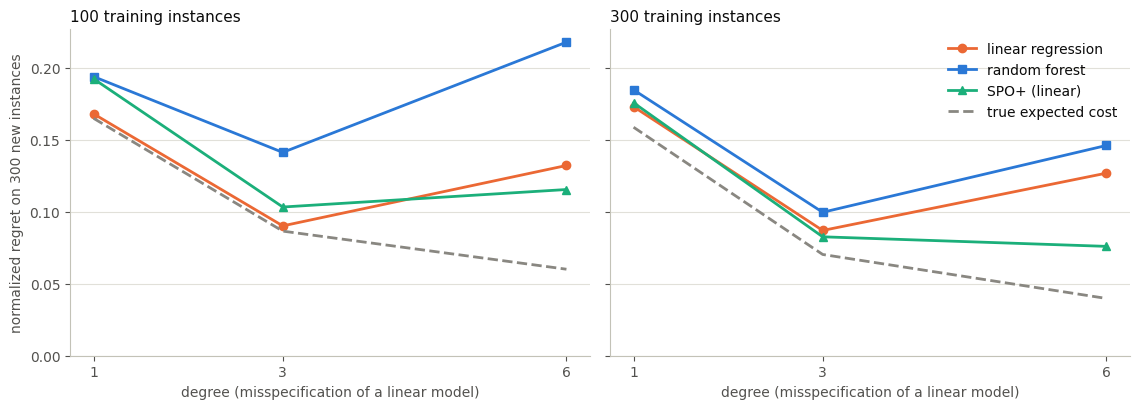

In [6]:
STYLE = {"linear regression": ("#eb6834", "-", "o"), "random forest": ("#2a78d6", "-", "s"),
         "SPO+ (linear)": ("#1baf7a", "-", "^"), "true expected cost": ("#898781", "--", None)}
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
for a, n in zip(ax, [100, 300]):
    sub = SP[SP.n_train == n]
    for m in METHODS:
        colour, ls, mk = STYLE[m]
        s = sub[sub.method == m]
        a.plot(s.degree, s.regret, ls=ls, marker=mk, ms=6, lw=2, color=colour, label=m)
    a.set_title(f"{n} training instances", loc="left", color=INK, fontsize=11)
    a.set_xlabel("degree (misspecification of a linear model)"); a.set_xticks([1, 3, 6]); tidy_axes(a)
ax[0].set_ylabel("normalized regret on 300 new instances"); ax[0].set_ylim(bottom=0)
ax[1].legend(frameon=False, labelcolor=INK)
plt.tight_layout(); plt.show()

### Reading the results

Compare each method with the dashed line (planning with the true expected costs), not with zero. At degree 1 even the
true expected cost has a regret of about 0.15: the expected costs of different paths are close and the ±50% noise
decides which path turns out cheapest, which no predictor can foresee.

* **Degree 1: the linear model is right, and least squares is best.** When the model can
  represent the expected costs, estimating them well is enough, and SPO+ can provide limited improvement.
* **Degree 6: the linear model is misspecified, and SPO+ pays off.**
* **More data helps SPO+, not least squares.** Least squares does not necessarily improve, because more data only pins down the line that is best for squared
  error, which is not the line that is best for decisions.
* **The random forest needs data.** With 100 instances it is the worst method from degree 2 on.

This is the pattern of the SPO+ paper: SPO+ is close to least squares when the model is well specified and clearly
better when it is not, which is the usual situation in practice. The paper averages 50 repetitions on 10,000 test
instances.

---
# Part 2: Our supplier MILP in PyEPO

## How to put your own optimization model into PyEPO

PyEPO needs your model in one form: a class whose only changing input is the cost vector. Everything else is PyEPO
or plain PyTorch:

| step | what | PyEPO class / function | what you write | in our example |
|---|---|---|---|---|
| 1 | the optimization model | subclass `optOmoModel` (Pyomo; `optGrbModel` for Gurobi) | `__init__` and `_getModel` | `SupplierModel` |
| 2 | the data | `optDataset(model, features, costs)` | nothing: it solves each instance once | `weeks` |
| 3 | the prediction model | any `torch.nn.Module` | `forward(features)`, returning `model.num_cost` numbers | `CostModel` |
| 4 | the loss | `pyepo.func.SPOPlus(model)` | nothing | `spo_plus` |
| 5 | training | a plain PyTorch loop | the loop | `train_four_weeks` |
| 6 | evaluation | `pyepo.metric.regret(predictor, model, loader)` | nothing | `train_four_weeks` |

Only step 1 is specific to your problem. The template for a Pyomo model:

```python
class MyModel(optOmoModel):
    def __init__(self, data, solver="highs"):
        self.data = data                 # (a) store what _getModel needs BEFORE calling super().__init__
        super().__init__(solver)         # (b) PyEPO calls _getModel, then adds the objective sum_k cost[k] * x[k]

    def _getModel(self):
        m = pe.ConcreteModel()
        m.x = pe.Var(...)                # (c) every variable with a cost coefficient, in one Var named m.x
        m.cons = pe.ConstraintList()     # (d) constraints only; no objective, PyEPO writes it
        m.cons.add(...)
        return m, m.x                    # (e) the model and the variables that carry the cost vector
```

Rules to remember:

* The cost vector has one entry per element of `m.x`, in index order; `model.num_cost` is its length, and the
  prediction model must return exactly that many numbers.
* Do not declare an objective: PyEPO builds $\sum_k \text{cost}_k\, x_k$ and minimizes it. For a maximization problem,
  set `self.modelSense = EPO.MAXIMIZE` inside `_getModel` (`from pyepo import EPO`).
* Name the variables `m.x` and the constraint list `m.cons`: PyEPO's `copy()` and `addConstr()` look for these names.
* Known cost terms (our fees) must also sit in `m.x` and in the cost vector. Here the prediction model appends them
  unchanged: the fees are "predicted perfectly", so in MILP-SPO+ their cost is $2f - f = f$, exactly as in the MILP
  notebook. (PyEPO 2.2's modelling language `pyepo.dsl` can instead keep them as fixed constants; exercise 3.)
* Integer variables are fine (`domain=pe.Binary`): PyEPO then solves a MILP each time, which is the slow part of
  training; `solve_ratio` reuses cached solutions (Part 1).

**Our MILP** has six variables, the shares $w_1, w_2, w_3$ and the binaries $y_1, y_2, y_3$, so its cost vector is
$(c_1, c_2, c_3, f_1, f_2, f_3)$ and `num_cost` is 6.

In [7]:
SUP = ["S1 local", "S2 regional", "S3 overseas"]
U   = [0.6, 0.7, 1.0]                      # capacities, share of the order (overseas can cover it alone)
fee = [0.2, 0.2, 0.8]                      # known weekly fee if a supplier is used
KEYS = ["w1", "w2", "w3", "y1", "y2", "y3"]  # the decision variables = the order of the cost vector

class SupplierModel(optOmoModel):                                    # step 1
    "min sum_j c_j w_j + sum_j f_j y_j  s.t.  sum_j w_j = 1,  w_j <= U_j y_j,  y_j binary,  0 <= w_j <= 1"

    def __init__(self, capacity, solver="highs"):
        self.capacity = list(capacity)           # (a) data first
        super().__init__(solver)                 # (b) PyEPO calls _getModel and adds the objective

    def _getModel(self):
        m = pe.ConcreteModel("supplier selection")
        m.x = pe.Var(KEYS, domain=lambda m, k: pe.Binary if k.startswith("y") else pe.UnitInterval)   # (c)
        m.cons = pe.ConstraintList()                                                                   # (d)
        m.cons.add(m.x["w1"] + m.x["w2"] + m.x["w3"] == 1)                       # the whole order is placed
        for j in range(3):                                                        # only used suppliers, up to capacity
            m.cons.add(m.x[f"w{j + 1}"] <= self.capacity[j] * m.x[f"y{j + 1}"])
        return m, m.x                                                                                  # (e)

milp_model = SupplierModel(U)
print("num_cost =", milp_model.num_cost)

# names for the plans, as on the slides (labels only)
PLAN_NAMES = {"A": [0, 0, 1], "B": [0.6, 0.4, 0], "C": [0.3, 0.7, 0], "D": [0.6, 0, 0.4], "E": [0, 0.7, 0.3]}
def plan(w): return next((n for n, p in PLAN_NAMES.items() if all(abs(w[j] - p[j]) < 1e-6 for j in range(3))), str(w))

# the four weeks of the MILP notebook
x = np.array([-0.4, -0.1, 0.1, 0.4])                                 # freight index - 1
c = np.array([[9.8, 8.2, 8.0], [10.0, 9.4, 8.9], [10.0, 10.2, 9.5], [10.2, 11.4, 15.4]])
costs = np.c_[c, np.tile(fee, (4, 1))]                               # (c1, c2, c3, f1, f2, f3) for each week

milp_model.setObj(costs[0])                                          # what PyEPO does with each cost vector
sol, obj = milp_model.solve()
print("week 1:", {k: round(float(v), 3) + 0.0 for k, v in zip(KEYS, sol)}, f" plan {plan(sol[:3])}, cost {obj:.2f}")

num_cost = 6
week 1: {'w1': 0.0, 'w2': 0.0, 'w3': 1.0, 'y1': 0.0, 'y2': 0.0, 'y3': 1.0}  plan A, cost 8.80


## Training it with PyEPO: the linear model on the four weeks

* **Step 2.** `optDataset` solves **MILP-c** once per week and stores $w^*(c)$ and $z^*(c)$.
* **Step 3.** `CostModel` wraps a *body* that predicts the three unit costs and appends the three known fees. Its output has 3 numbers because there are **three suppliers**: one
  predicted unit cost each. With one feature (the freight index $x$), the layer holds a $3 \times 1$ weight (the three
  slopes) and 3 biases (the three intercepts), i.e. the three lines $\hat c_j = \theta_{j0} + \theta_{j1} x$ of the
  slides. With the fees appended, `CostModel` returns the 6 numbers `SupplierModel` expects. (In Part 1 the linear
  model has 40 outputs, one per edge.)
* **Step 4.** `SPOPlus` solves **MILP-SPO+** (unit costs $2\hat c - c$, fees unchanged) in the forward pass; the
  backward pass is $2(w^*(c) - w^*(2\hat c - c))$, and PyTorch's chain rule takes it to the slopes and intercepts.
* **Steps 5–6.** Plain gradient descent (`SGD`, step 0.75) on all four weeks at once, started from least squares,
  is exactly the procedure of the slides and the MILP notebook (sections 3–4). `train_four_weeks` also records the
  plans and the regret (`pyepo.metric.regret`) along the way.

In [8]:
FEE = torch.tensor(fee, dtype=torch.float32)

class CostModel(torch.nn.Module):                                    # step 3
    "body: features -> the 3 unit costs; the 3 known fees are appended -> the 6 costs of SupplierModel"
    def __init__(self, body):
        super().__init__()
        self.body = body
    def forward(self, features):
        unit_costs = self.body(features)                             # (weeks, 3): one per supplier
        return torch.cat([unit_costs, FEE.expand(len(features), 3)], dim=1)   # (weeks, 6) = milp_model.num_cost

weeks = pyepo.data.dataset.optDataset(milp_model, x[:, None].astype(np.float32), costs.astype(np.float32))  # step 2
all_weeks = DataLoader(weeks, batch_size=4, shuffle=False)          # one batch = the four weeks
print("z*(c) from MILP-c:", weeks.objs.ravel().numpy().round(2))

def train_four_weeks(net, optimizer, iterations, report_every=1):
    "steps 4-6: the SPO+ loss, a plain PyTorch loop, and the plans and regret along the way"
    spo_plus = pyepo.func.SPOPlus(milp_model)                       # MILP-SPO+ solved for every week, every step
    hist = []
    for it in range(iterations + 1):
        feats, cb, wb, zb = next(iter(all_weeks))
        c_hat = net(feats)
        loss = spo_plus(c_hat, cb, wb, zb)                          # forward: MILP-SPO+ for each week
        if it % report_every == 0:
            decisions = []
            for i in range(4):                                      # MILP-ĉ: the plan each week gets
                milp_model.setObj(c_hat[i].detach().numpy())
                decisions.append(plan(milp_model.solve()[0][:3]))
            hist.append(dict(iteration=it, plans=" ".join(decisions), mean_spo=round(loss.item(), 3) + 0.0,
                             mean_regret=pyepo.metric.regret(net, milp_model, all_weeks, reduction="mean")))  # step 6
        optimizer.zero_grad(); loss.backward(); optimizer.step()    # backward: 2 (w*(c) - w*(2 c_hat - c)), update
    return pd.DataFrame(hist).set_index("iteration")

theta_ls = np.array([np.polyfit(x, c[:, j], 1)[::-1] for j in range(3)])   # least squares: intercept, slope
line = CostModel(torch.nn.Linear(1, 3))                              # three lines: c_hat_j = theta_j0 + theta_j1 x
with torch.no_grad():
    line.body.bias.copy_(torch.tensor(theta_ls[:, 0]))               # the three intercepts
    line.body.weight.copy_(torch.tensor(theta_ls[:, 1:]))            # the three slopes (a 3 x 1 weight)
print("start (least squares): intercepts", theta_ls[:, 0].round(3), " slopes", theta_ls[:, 1].round(3))
train_four_weeks(line, torch.optim.SGD(line.parameters(), lr=0.75), iterations=3)

z*(c) from MILP-c: [ 8.8   9.7  10.3  11.08]
start (least squares): intercepts [10.    9.8  10.45]  slopes [0.471 4.    8.882]


,plans,mean_spo,mean_regret
iteration,,,
0,A C B B,1.128,0.115
1,A A B B,0.301,0.045
2,A A A B,0.284,0.000
3,A A A B,0.258,0.000


Same plans (A C B B → A A B B → A A A B), mean SPO+ (1.128 → 0.301 → 0.284 → 0.258) and mean regret
(0.115 → 0.045 → 0 → 0) as the hand computation in the MILP notebook; `line.body.bias` and `line.body.weight` now
hold the intercepts and slopes after the three steps, as in its tables. PyEPO does exactly what the slides do, and
the same few lines work for any model and any number of weeks.

## The same loop with a small neural network

Only the body changes: `torch.nn.Sequential(Linear(1, 8), ReLU(), Linear(8, 3))`, a hidden layer of 8 units and still
three outputs, one per supplier. Its last bias starts at the mean costs of the four weeks, so the first predictions are
sensible. Adam is the usual optimizer for networks.

In [9]:
torch.manual_seed(0)
network = CostModel(torch.nn.Sequential(torch.nn.Linear(1, 8), torch.nn.ReLU(), torch.nn.Linear(8, 3)))
with torch.no_grad():
    network.body[2].bias.copy_(torch.tensor(c.mean(axis=0)))       # start at the mean unit costs
train_four_weeks(network, torch.optim.Adam(network.parameters(), lr=0.05), iterations=60, report_every=10)

,plans,mean_spo,mean_regret
iteration,,,
0,C C C C,2.602,0.290
10,A A A A,1.325,1.280
20,A A B B,0.365,0.045
30,A A A B,0.000,0.000
40,A A A B,0.000,0.000
50,A A A B,0.000,0.000
60,A A A B,0.000,0.000


The network starts at the mean costs, so every week gets the same plan (C), like the deterministic model of the MILP
notebook. It overshoots on the way (at step 10 week 4 also gets plan A, with a regret of 1.28) and after about 30 steps
has the best plan in every week and a training SPO+ of **zero**. With four weeks and 8 hidden units a network can fit
every decision exactly (overfitting). We need more data and a test set, as in Part 1
(exercise 2).

---
# Exercises

1. **Scale the toy up.** Generate 100 training weeks and 1,000 test weeks with the cost structure of section 6 of the
   MILP notebook, `truth(x) = [10 + 0.5x, 9.8 + 4x, 9.2 + 3x + 25 max(0, x - 0.2)]` plus normal noise (sd 0.2), with
   $x \sim U[-0.5, 0.5]$. Train `CostModel` with the line and with the network, using minibatches of 20, Adam,
   `SPOPlus(milp_model, solve_ratio=0.3, dataset=train)` and about 30 epochs, and compare their normalized test regret
   (`pyepo.metric.regret`) with least squares. Which plans end up in `spo_plus.solpool`?
2. **Fees as known constants.** PyEPO 2.2 also has a modelling language (`pyepo.dsl`) in which only part of the
   objective is a predicted `Parameter` and the rest (our fees) is a known constant. Rewrite `SupplierModel` with it
   and check that the four-week training gives the same iterations. Start from

   ```python
   from pyepo import EPO, dsl
   w, y, c_par = dsl.Variable(3, lb=0, ub=1), dsl.Variable(3, vtype=EPO.BINARY), dsl.Parameter(3)
   prob = dsl.Problem(dsl.Minimize(dsl.sum(c_par * w) + dsl.sum(np.array(fee) * y)),
                      [dsl.sum(w) == 1, w - np.array(U) * y <= 0])
   dsl_model = prob.compile("pyomo", solver="highs")    # num_cost = 3: predict only the unit costs
   ```

   With this model the prediction model returns the three unit costs only (no fees appended).